## 1. Revisar cómo importar ejemplos de matrices desde la base de datos SuiteSparse

Link para descargar http://sparse.tamu.edu/

In [ ]:
pip install scipy numpy matplotlib

In [ ]:
!ls

bcspwr01  bcspwr01.tar.gz  sample_data


In [ ]:
!tar -xzf bcspwr01.tar.gz

In [ ]:
!ls

bcspwr01  bcspwr01.tar.gz  sample_data


In [ ]:
!find ./bcspwr01 -name "*.mtx"

./bcspwr01/bcspwr01.mtx


In [ ]:
from scipy.io import mmread

A = mmread("./bcspwr01/bcspwr01.mtx")

print("Tamaño:", A.shape)
print("Elementos no cero:", A.nnz)

Tamaño: (39, 39)
Elementos no cero: 131


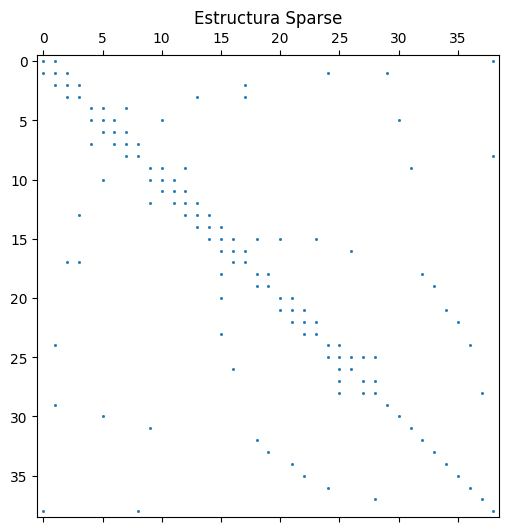

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.spy(A, markersize=1)
plt.title("Estructura Sparse")
plt.show()

In [ ]:
!pip install networkx

In [ ]:
import networkx as nx
from scipy.io import mmread

A = mmread("./bcspwr01/bcspwr01.mtx")

G = nx.from_scipy_sparse_array(A)

print("Nodos:", G.number_of_nodes())
print("Aristas:", G.number_of_edges())

Nodos: 39
Aristas: 85


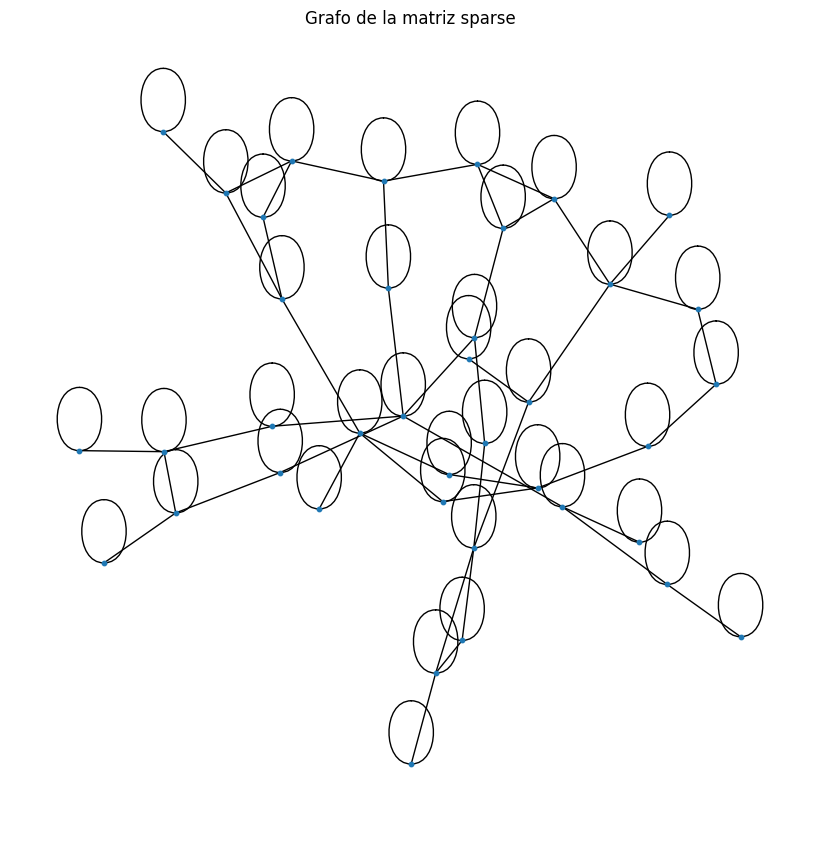

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,8))

nx.draw(
    G,
    node_size=10,
    with_labels=False
)

plt.title("Grafo de la matriz sparse")
plt.show()

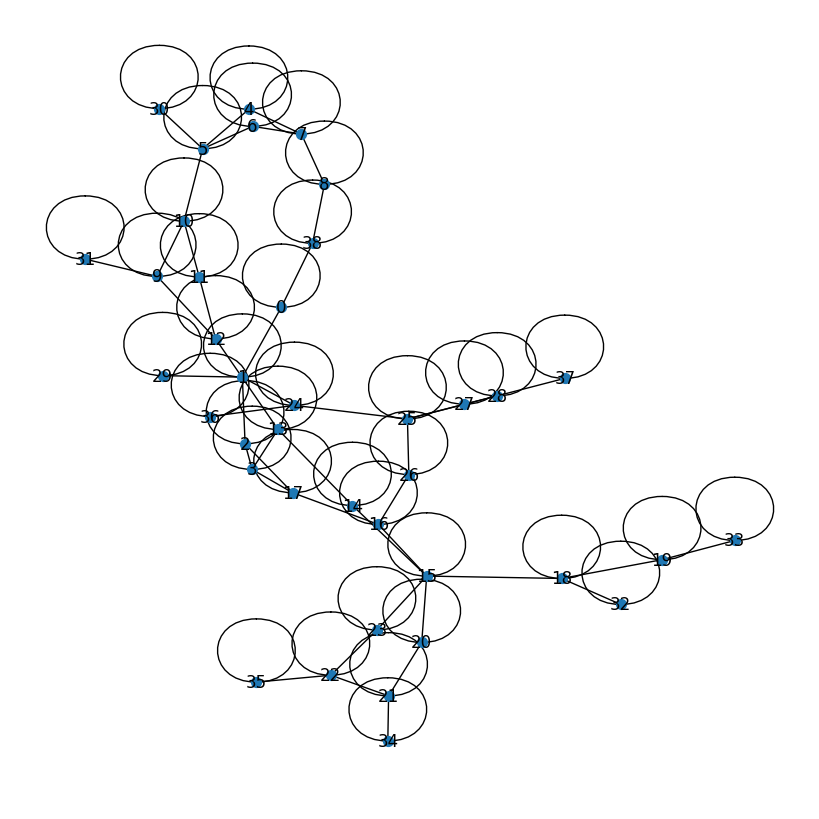

In [ ]:
G_small = G.subgraph(range(50))

plt.figure(figsize=(8,8))

nx.draw(
    G_small,
    node_size=50,
    with_labels=True
)

plt.show()

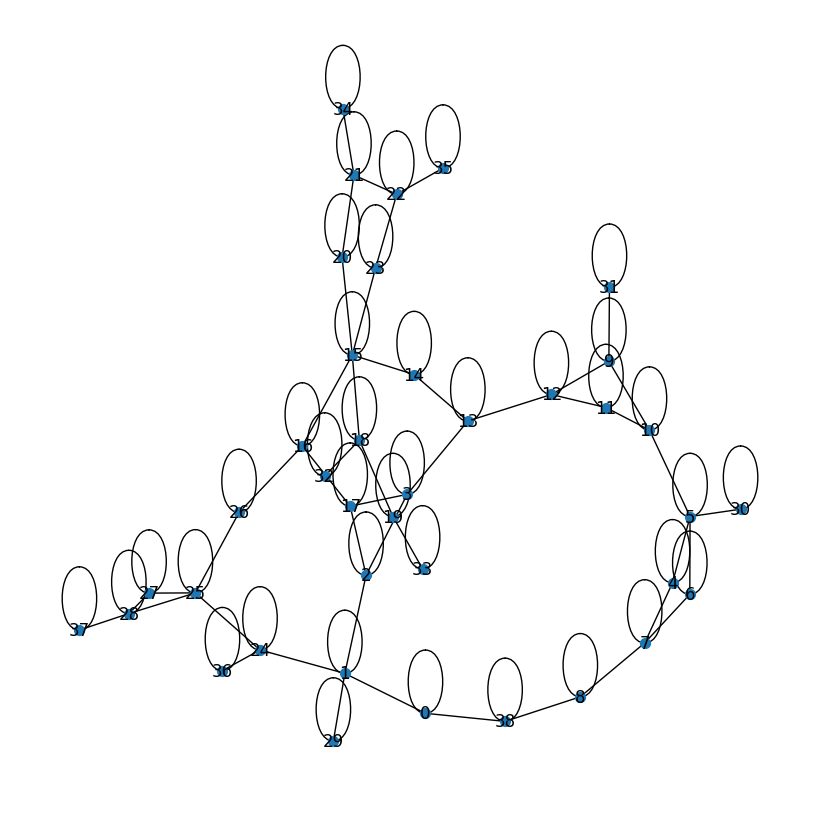

In [ ]:
plt.figure(figsize=(8,8))

pos = nx.spring_layout(G_small)

nx.draw(
    G_small,
    pos,
    node_size=50,
    with_labels=True
)

plt.show()

## 2. Estudiar ejemplos de implementación de redes neuronales con PyTorch

In [ ]:
import torch
import torch.nn as nn

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# Datos
x = torch.tensor([[1.0], [2.0], [3.0], [4.0]])
y = torch.tensor([[3.0], [5.0], [7.0], [9.0]])

# Modelo lineal
model = nn.Linear(1,1)

criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

# Entrenamiento
for epoch in range(1000):

    y_pred = model(x)

    loss = criterion(y_pred, y)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    # Resultado
print(model.weight)
print(model.bias)

Parameter containing:
tensor([[1.9929]], requires_grad=True)
Parameter containing:
tensor([1.0207], requires_grad=True)


**Datos de entrenamiento**

Los datos representan la relación:

x = 1, 2, 3, 4

y = 3, 5, 7, 9

Estos valores siguen la ecuación:

y=2x+1

**Definición del modelo**

La red neuronal tiene:

* 1 entrada
* 1 salida

y representa una función lineal de la forma:

$y=wx+b$

donde:

* $w$ es el peso,
* $b$ es el bias.

Inicialmente PyTorch asigna valores aleatorios a estos parámetros.

**Función de pérdida**

Se utiliza el error cuadrático medio:

$$MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2$$

Esta función mide la diferencia entre:

* los valores reales,
* y las predicciones de la red.

El objetivo del entrenamiento es minimizar este error.

**Optimizador**

Se utiliza el algoritmo Stochastic Gradient Descent (SGD).

El optimizador ajusta automáticamente:

* pesos,
* bias,

para reducir el error de predicción.

El parámetro $lr=0.01$ representa la tasa de aprendizaje.

**Entrenamiento de la red**

Durante cada iteración:

* La red realiza predicciones.
* Se calcula el error.
* Se calculan derivadas automáticamente mediante backpropagation.
* Se actualizan los parámetros del modelo.

Este proceso se repite 1000 veces para que la red aprenda la relación entre x y y.

**Resultados obtenidos**

La red aprende valores cercanos a:

* $w≈2$
* $b≈1$

por lo tanto el modelo reconstruye correctamente la ecuación: $y=2x+1$

**Interpretación del aprendizaje**

La red neuronal comienza con parámetros aleatorios y, mediante optimización iterativa, ajusta automáticamente:

* la pendiente,
* y el término independiente,

hasta aproximar la función correcta.






In [ ]:
import torch
import torch.nn as nn

class Red(nn.Module):

    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(2, 8)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(8, 1)

    def forward(self, x):

        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)

        return x

model = Red()

print(model)

Red(
  (fc1): Linear(in_features=2, out_features=8, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=8, out_features=1, bias=True)
)


**Explicación de la arquitectura**

La red tiene la siguiente estructura:

2→8→1

Esto significa:

- 2 entradas
- 1 capa oculta con 8 neuronas
- 1 salida

**Capa lineal**

Representa una transformación lineal:

$$Wx+b$$

donde:

* W son los pesos,
* x es la entrada,
* b es el bias.

La capa recibe 2 variables de entrada y produce 8 salidas internas.

**Función de activación ReLU**

Aplica la función:

$$ReLU(x)=max(0,x)$$

Su objetivo es introducir no linealidad en la red neuronal.

* Si el valor es positivo → permanece igual.
* Si el valor es negativo → se convierte en 0.

**Segunda capa lineal**

Toma las 8 neuronas ocultas y genera una única salida final.

**Método Forward**

Define cómo fluye la información dentro de la red:

* Entrada
* Primera capa lineal
* Activación ReLU
* Segunda capa lineal
* Salida

**Interpretación de la salida**

* in_features=2:

la red recibe 2 variables de entrada.
* out_features=8:

la primera capa genera 8 neuronas ocultas.
* ReLU():

función de activación no lineal.
* out_features=1:

la red produce una única salida.
* bias=True:

cada neurona posee un término independiente.